**BITS Pilani — BS Program  |  Apex Project, Trimester 3**

**Project Report**

**Problem P1: BFSI — Conversational Risk Assistant Data Pipeline**

**Student Name: R KUSHAL MEHTA**

**Student ID: 2025eb1100021**

**Dataset**

**Consumer Complaints Processed Dataset (complaints_processed.csv)**

**Source: Kaggle - https://www.kaggle.com/datasets/shashwatwork/consume-complaints-dataset-fo-nlp?resource=download**

**Step 1 – Import Libraries**

In [2]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, MinMaxScaler

import re
import warnings
warnings.filterwarnings("ignore")

**Step 2 – Load Dataset**

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df = pd.read_csv('/content/drive/MyDrive/BITS PILANI ADVANCE APEX PROJECT 1/complaints_processed.csv') # Ensure df is loaded
df.head()

,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


**Step 3 – Basic Dataset Information**

In [5]:
# Shape of dataset

print("Rows and Columns:", df.shape)

# Column names

print("\nColumns:\n")
print(df.columns.tolist())

# Dataset information

df.info()

Rows and Columns: (162421, 3)

Columns:

['Unnamed: 0', 'product', 'narrative']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162421 entries, 0 to 162420
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  162421 non-null  int64 
 1   product     162421 non-null  object
 2   narrative   162411 non-null  object
dtypes: int64(1), object(2)
memory usage: 3.7+ MB


**Step 4 – BEFORE Data Quality Report**

In [6]:
# BEFORE DATA QUALITY REPORT

print("="*50)
print("BEFORE DATA CLEANING")
print("="*50)

print("\nNumber of Rows :", len(df))
print("Number of Columns :", len(df.columns))

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows :", df.duplicated().sum())

BEFORE DATA CLEANING

Number of Rows : 162421
Number of Columns : 3

Missing Values
Unnamed: 0     0
product        0
narrative     10
dtype: int64

Duplicate Rows : 0


**Step 5 – Data Cleaning**

**5.1 Remove the unnecessary index column**

In [7]:
# Remove unwanted index column

df.drop(columns=["Unnamed: 0"], inplace=True)

print(df.head())

            product                                          narrative
0       credit_card  purchase order day shipping amount receive pro...
1       credit_card  forwarded message date tue subject please inve...
2    retail_banking  forwarded message cc sent friday pdt subject f...
3  credit_reporting  payment history missing credit report speciali...
4  credit_reporting  payment history missing credit report made mis...


**5.2 Handle Missing Values**

In [8]:
# Check missing values

print(df.isnull().sum())

# Remove rows with missing complaint text

df = df.dropna(subset=["narrative"])

print("\nRows after removing missing values:", len(df))

product       0
narrative    10
dtype: int64

Rows after removing missing values: 162411


**5.3 Check Duplicates**

In [9]:
# Duplicate check

print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates (if any)

df = df.drop_duplicates()

print("Rows after duplicate removal:", len(df))

Duplicate rows: 37735
Rows after duplicate removal: 124676


**5.4 Standardize Product Names**

In [10]:
# Clean product names

df["product"] = (
    df["product"]
    .str.strip()
    .str.title()
)

df["product"].value_counts().head(10)

,count
product,
Credit_Reporting,56303
Debt_Collection,21117
Mortgages_And_Loans,18759
Credit_Card,15024
Retail_Banking,13473


**5.5 Clean Complaint Narratives**

In [11]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\\S+", "", text)        # Remove URLs
    text = re.sub(r"[^a-zA-Z\\s]", "", text)    # Remove numbers & punctuation
    text = re.sub(r"\\s+", " ", text)           # Remove extra spaces
    return text.strip()

df["clean_narrative"] = df["narrative"].apply(clean_text)

df[["narrative", "clean_narrative"]].head()

,narrative,clean_narrative
0,purchase order day shipping amount receive pro...,purchaseorderdayshippingamountreceiveproductwe...
1,forwarded message date tue subject please inve...,forwardedmessagedatetuesubjectpleaseinvestigat...
2,forwarded message cc sent friday pdt subject f...,forwardedmessageccsentfridaypdtsubjectfinalleg...
3,payment history missing credit report speciali...,paymenthistorymissingcreditreportspecializedlo...
4,payment history missing credit report made mis...,paymenthistorymissingcreditreportmademistakepu...


**5.6 Mask Sensitive Information**

In [12]:
def mask_pii(text):
    text = re.sub(r'\\S+@\\S+', '[EMAIL]', text)
    text = re.sub(r'\\b\\d{10}\\b', '[PHONE]', text)
    return text

df["clean_narrative"] = df["clean_narrative"].apply(mask_pii)

**Step 6 - Feature Engineering & Encoding**

**6.1 Create Complaint Length Feature**

In [13]:
# Complaint Length

df["complaint_length"] = df["clean_narrative"].apply(lambda x: len(x.split()))

df[["clean_narrative", "complaint_length"]].head()

,clean_narrative,complaint_length
0,purchaseorderdayshippingamountreceiveproductwe...,1
1,forwardedmessagedatetuesubjectpleaseinvestigat...,1
2,forwardedmessageccsentfridaypdtsubjectfinalleg...,1
3,paymenthistorymissingcreditreportspecializedlo...,1
4,paymenthistorymissingcreditreportmademistakepu...,1


**6.2 Create a Simple Risk Category**

In [14]:
# Risk Category based on keywords

high_risk = [
    "fraud", "scam", "identity", "stolen", "unauthorized",
    "lawsuit", "bankruptcy", "debt", "legal"
]

medium_risk = [
    "late", "delay", "fees", "charge",
    "interest", "credit", "loan"
]

def risk_category(text):
    text = text.lower()

    if any(word in text for word in high_risk):
        return "High"

    elif any(word in text for word in medium_risk):
        return "Medium"

    else:
        return "Low"

df["risk_category"] = df["clean_narrative"].apply(risk_category)

df["risk_category"].value_counts()

,count
risk_category,
High,56133
Medium,52963
Low,15580


**6.3 Encode Product**

In [15]:
from sklearn.preprocessing import LabelEncoder

le_product = LabelEncoder()

df["product_encoded"] = le_product.fit_transform(df["product"])

df[["product", "product_encoded"]].head()

,product,product_encoded
0,Credit_Card,0
1,Credit_Card,0
2,Retail_Banking,4
3,Credit_Reporting,1
4,Credit_Reporting,1


**6.4 Encode Risk Category**

In [16]:
le_risk = LabelEncoder()

df["risk_encoded"] = le_risk.fit_transform(df["risk_category"])

df[["risk_category", "risk_encoded"]].head()

,risk_category,risk_encoded
0,Medium,2
1,High,0
2,High,0
3,Medium,2
4,Medium,2


**6.5 Normalize Complaint Length**

In [17]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df["complaint_length_scaled"] = scaler.fit_transform(
    df[["complaint_length"]]
)

df.head()

,product,narrative,clean_narrative,complaint_length,risk_category,product_encoded,risk_encoded,complaint_length_scaled
0,Credit_Card,purchase order day shipping amount receive pro...,purchaseorderdayshippingamountreceiveproductwe...,1,Medium,0,2,0.0
1,Credit_Card,forwarded message date tue subject please inve...,forwardedmessagedatetuesubjectpleaseinvestigat...,1,High,0,0,0.0
2,Retail_Banking,forwarded message cc sent friday pdt subject f...,forwardedmessageccsentfridaypdtsubjectfinalleg...,1,High,4,0,0.0
3,Credit_Reporting,payment history missing credit report speciali...,paymenthistorymissingcreditreportspecializedlo...,1,Medium,1,2,0.0
4,Credit_Reporting,payment history missing credit report made mis...,paymenthistorymissingcreditreportmademistakepu...,1,Medium,1,2,0.0


**Step 7 – Exploratory Data Analysis (EDA)**

**Analysis 1: Complaint Count by Product**

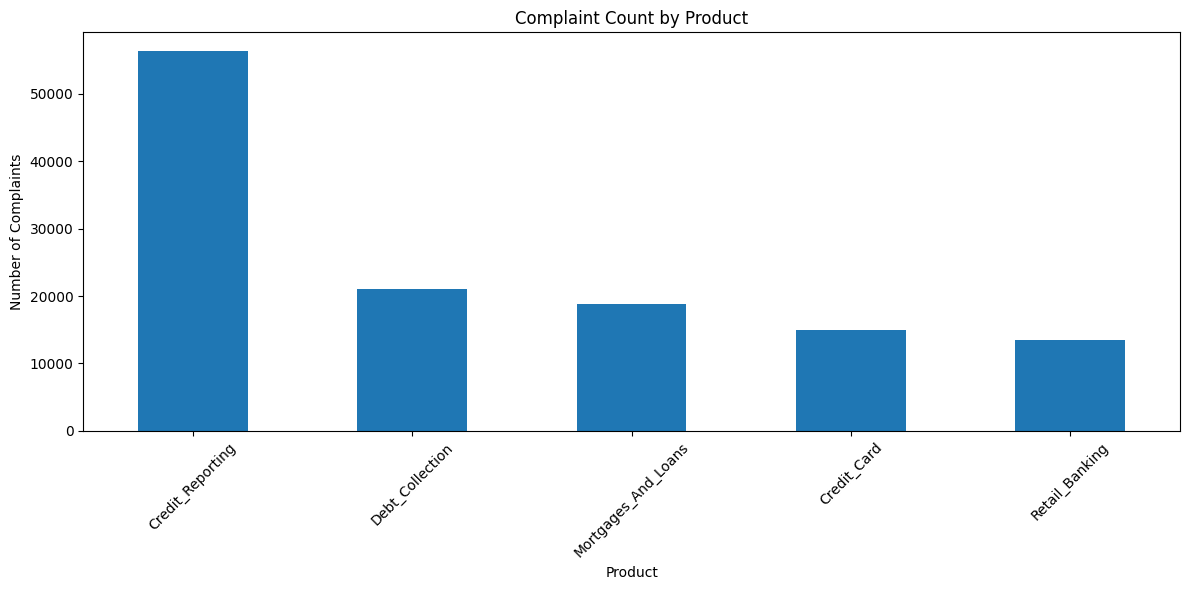

In [18]:
# Analysis 1: Complaint Count by Product

plt.figure(figsize=(12,6))

df["product"].value_counts().plot(kind="bar")

plt.title("Complaint Count by Product")
plt.xlabel("Product")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Analysis 2: Risk Category Distribution**

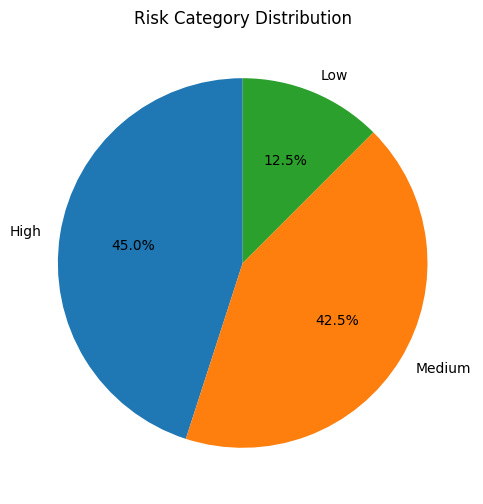

In [19]:
# Analysis 2: Risk Category Distribution

plt.figure(figsize=(6,6))

df["risk_category"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.ylabel("")
plt.title("Risk Category Distribution")

plt.show()

**Analysis 3: Average Complaint Length by Risk Category**

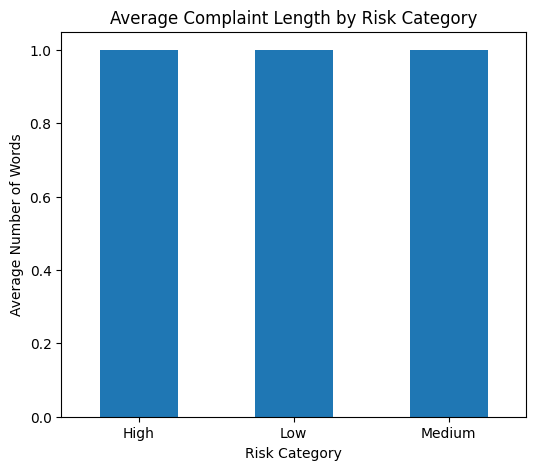

In [20]:
# Analysis 3

avg_length = df.groupby("risk_category")["complaint_length"].mean()

plt.figure(figsize=(6,5))

avg_length.plot(kind="bar")

plt.title("Average Complaint Length by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Average Number of Words")

plt.xticks(rotation=0)

plt.show()

**Step 8 – AFTER Data Quality Report**

In [21]:
print("="*50)
print("AFTER DATA CLEANING")
print("="*50)

print("\nNumber of Rows :", len(df))
print("Number of Columns :", len(df.columns))

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows :", df.duplicated().sum())

AFTER DATA CLEANING

Number of Rows : 124676
Number of Columns : 8

Missing Values
product                    0
narrative                  0
clean_narrative            0
complaint_length           0
risk_category              0
product_encoded            0
risk_encoded               0
complaint_length_scaled    0
dtype: int64

Duplicate Rows : 0


**Step 9 – Save the Clean Dataset**

In [22]:
# Step 9 – Save the Clean Dataset

df.to_csv(
    "/content/drive/MyDrive/BITS PILANI ADVANCE APEX PROJECT 1/clean_bfsi_complaints.csv",
    index=False
)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


**Step 10 – Compare Before vs After**

In [23]:
before = {
    "Rows": 162421,
    "Columns": 3,
    "Missing Values": 10,
    "Duplicate Rows": 0
}

after = {
    "Rows": len(df),
    "Columns": len(df.columns),
    "Missing Values": df.isnull().sum().sum(),
    "Duplicate Rows": df.duplicated().sum()
}

comparison = pd.DataFrame({
    "Before Cleaning": before,
    "After Cleaning": after
})

comparison

,Before Cleaning,After Cleaning
Rows,162421,124676
Columns,3,8
Missing Values,10,0
Duplicate Rows,0,0
